# 01 · CUSUM basics: false alarms, detection delay and the log(ARL)/KL rule

**Goal.** Build the simplest quickest-change detector (CUSUM) from scratch, measure its two performance numbers by Monte Carlo, and check them against theory:

- **ARL** (average run length to false alarm): how many samples of *normal* data the detector sees, on average, before it raises a false alarm. Bigger is better.
- **Delay**: how many samples after a fault starts it takes to raise the alarm. Smaller is better.

Theory says **delay ≈ log(ARL) / KL**. We test how good that rule is, and where it breaks.

**Run it** from the project root (1 to 4 minutes on a laptop, depending on what else is running). Tables and figures are written to `results/01_cusum_basics/`.

```
.venv\Scripts\python -m nbconvert --to notebook --execute --inplace notebooks/01_cusum_basics.ipynb
```

**Sections:** 1 The problem · 2 Likelihood ratio and KL · 3 CUSUM · 4 Why log(ARL)/KL · 5 Monte Carlo · 6 Theory vs simulation · 7 Correlated noise · 8 When the change happens later · 9 Summary and exercises

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261022                      # every random stream below derives from this
OUT = Path("../results/01_cusum_basics")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")                       # LaTeX write-up: figures, tables and key numbers go here
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)
(REPORT / "figures").mkdir(parents=True, exist_ok=True)
(REPORT / "tables").mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png")                       # quick look
    fig.savefig(REPORT / "figures" / f"01_{name}.pdf")     # vector copy for the report

def save_tex_table(df, name, column_format):
    # tabular only; caption and label live in report/main.tex
    (REPORT / "tables" / f"01_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    # key results as \newcommand macros, so the report's prose updates when the notebook is re-run
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"01_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

def rng_for(k):
    # independent, reproducible random stream number k
    return np.random.default_rng([SEED, k])

# plot style: light surface, recessive grid and axes, 2px lines
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 7, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

## 1. The problem

Observations $x_1, x_2, \dots$ are independent. Up to an unknown time $\nu$ they are $\mathcal N(0,1)$; from sample $\nu+1$ on they are $\mathcal N(\delta,1)$.

- Think of $x_n$ as a KPI **residual**: for example slice latency minus its normal level, divided by its normal standard deviation. Then $\delta$ is the fault size in units of noise standard deviations.
- Detection-theory view: every sample is a small binary hypothesis test, $H_0$: mean 0 vs $H_1$: mean $\delta$, like deciding "signal present?" in a noisy receiver. The twist is that we don't know *when* $H_1$ starts, and we must decide online, one sample at a time.
- The trade-off is the time version of $P_{FA}$ vs $P_D$: a low threshold catches faults quickly but raises false alarms often.

In [2]:
delta, nu, n_total = 1.0, 100, 200            # fault of 1 noise-sd, starting after sample 100
n = np.arange(1, n_total + 1)
true_mean = np.where(n > nu, delta, 0.0)
x = true_mean + rng_for(0).standard_normal(n_total)
print(f"mean before change: {x[:nu].mean():+.2f}   mean after change: {x[nu:].mean():+.2f}")

mean before change: -0.02   mean after change: +0.86


## 2. Log-likelihood ratio and KL divergence

For one sample, the log-likelihood ratio is $\ell(x) = \log \dfrac{f_1(x)}{f_0(x)}$. For unit-variance Gaussians:

$$\ell(x) = \log \frac{e^{-(x-\delta)^2/2}}{e^{-x^2/2}} = \delta x - \frac{\delta^2}{2}.$$

- Signals link: $\delta \cdot x$ is a **correlator (matched filter)** with the known signal level $\delta$. Subtracting $\delta^2/2$ puts the decision boundary halfway between the two means, at $x = \delta/2$.
- Its average under each hypothesis:
  - before the fault, $x \sim \mathcal N(0,1)$: $\;E_0[\ell] = -\delta^2/2$
  - after the fault, $x \sim \mathcal N(\delta,1)$: $\;E_1[\ell] = +\delta^2/2$
- $\delta^2/2$ is the **KL divergence** $D(f_1 \| f_0)$: the average evidence for "fault" that one post-fault sample carries. It is the one number that sets how fast *any* detector can be.

Check the two means numerically:

In [3]:
def llr(x, delta):
    # log f1(x)/f0(x) for N(delta,1) vs N(0,1)
    return delta * x - delta**2 / 2

KL = delta**2 / 2
z = rng_for(1).standard_normal(10**6)
print(f"KL = delta^2/2 = {KL:.3f}")
print(f"E0[llr]: simulated {llr(z, delta).mean():+.4f}   theory {-KL:+.4f}")
print(f"E1[llr]: simulated {llr(z + delta, delta).mean():+.4f}   theory {+KL:+.4f}")

KL = delta^2/2 = 0.500
E0[llr]: simulated -0.5003   theory -0.5000
E1[llr]: simulated +0.4997   theory +0.5000


## 3. CUSUM

Add up the evidence, but never let the total go below zero:

$$W_0 = 0, \qquad W_n = \max\big(0,\; W_{n-1} + \ell(x_n)\big), \qquad \text{alarm at } T = \min\{n : W_n \ge h\}.$$

- Before the fault, $\ell$ has negative mean, so $W$ drifts down and keeps getting reset to 0: the detector forgets old normal data.
- After the fault, $\ell$ has mean $+\text{KL}$, so $W$ climbs by about KL per sample until it crosses $h$.
- Project link: this is exactly **Lindley's recursion** for the waiting time in a queue, $W_n = \max(0, W_{n-1} + S_n - A_n)$. CUSUM is a queue whose "arriving work" is the evidence $\ell$: a stable queue before the fault, an overloaded one after. The same recursion will come back in the slice simulator.

change after n = 100, alarm at n = 109, delay = 9 samples


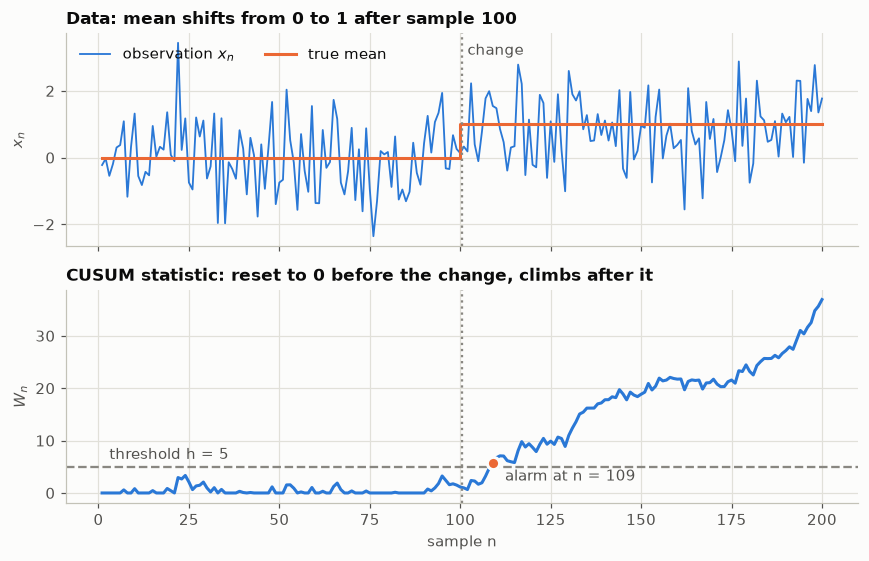

In [4]:
def cusum(x, delta):
    # CUSUM statistic W_1..W_n for one data sequence
    W = np.empty(len(x))
    w = 0.0
    for i, xi in enumerate(x):
        w = max(0.0, w + llr(xi, delta))
        W[i] = w
    return W

h_demo = 5.0
W = cusum(x, delta)
alarm = int(np.argmax(W >= h_demo)) + 1          # first n with W_n >= h (1-based)
print(f"change after n = {nu}, alarm at n = {alarm}, delay = {alarm - nu} samples")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5.2), sharex=True)
ax1.plot(n, x, color=BLUE, lw=1.2, label="observation $x_n$")
ax1.step(n, true_mean, where="pre", color=ORANGE, label="true mean")
ax1.set_ylabel("$x_n$")
ax1.set_title("Data: mean shifts from 0 to 1 after sample 100")
ax1.legend(loc="upper left", ncol=2)
ax2.plot(n, W, color=BLUE, label="CUSUM $W_n$")
ax2.axhline(h_demo, color=MUTED, ls="--", lw=1.5)
ax2.text(3, h_demo + 0.8, f"threshold h = {h_demo:g}", color=INK2, va="bottom")
ax2.plot([alarm], [W[alarm - 1]], "o", color=ORANGE, markersize=8, mec=SURFACE, mew=2)
ax2.annotate(f"alarm at n = {alarm}", (alarm, W[alarm - 1]), xytext=(8, -4),
             textcoords="offset points", color=INK2, va="top")
ax2.set_xlabel("sample n")
ax2.set_ylabel("$W_n$")
ax2.set_title("CUSUM statistic: reset to 0 before the change, climbs after it")
for ax in (ax1, ax2):
    ax.axvline(nu + 0.5, color=MUTED, ls=":", lw=1.5)
ax1.text(nu + 2, ax1.get_ylim()[1] * 0.92, "change", color=INK2, va="top")
fig.tight_layout()
save_fig(fig, "fig1_cusum_path")
plt.show()

## 4. Why delay ≈ log(ARL) / KL

Two back-of-envelope facts:

1. **Delay.** After the fault, $W$ climbs by about KL per sample, so reaching $h$ takes about $h/\text{KL}$ samples.
2. **ARL.** Before the fault, a false alarm needs $W$ to climb $h$ against its downward drift. Because $E_0\big[e^{\ell(x)}\big] = \int f_1(x)\,dx = 1$, the quantity $e^{W}$ behaves like a fair game (a martingale), so one upward excursion from 0 reaches $h$ with probability at most $e^{-h}$. Each excursion falls back to 0 after a few samples, so we wait for roughly $e^{h}$ excursions: $\text{ARL} \gtrsim e^{h}$, i.e. $h \approx \log \text{ARL}$.

Together: $\boxed{\text{delay} \approx \log(\text{ARL}) / \text{KL}}$. Writing the false-alarm rate as $\alpha \approx 1/\text{ARL}$ gives the $|\log\alpha|/\text{KL}$ form in Veeravalli & Banerjee (reference 1 in `docs/project_reference.md`). Consequences:

- delay grows only *logarithmically* with ARL: 10× fewer false alarms costs a fixed number of extra samples, $\log 10/\text{KL}$;
- delay scales like $1/\delta^2$: a fault half the size takes about 4× longer to catch.

This is a **first-order** result, exact only as ARL → ∞. It ignores the overshoot of $W$ past $h$ and the time $W$ spends stuck at 0. For the Gaussian case there is a sharper formula, **Siegmund's approximation**:

$$\text{ARL}(\mu) \approx \frac{e^{-2Db} + 2Db - 1}{2D^2}, \qquad b = \frac{h}{\delta} + 1.166, \qquad D = \mu - \frac{\delta}{2},$$

where $\mu$ is the true mean of $x$. With $\mu = 0$ it gives the ARL to false alarm. With $\mu = \delta$ (fault present from the first sample) the "run length" *is* the delay. Our $W$ equals $\delta$ times the textbook CUSUM $\sum (x - \delta/2)$, which is why the textbook threshold is $h/\delta$.

*Source note:* the formula is quoted from memory of Siegmund's book *Sequential Analysis* (1985); we have not opened it. The Monte Carlo below is the check.

In [5]:
def first_order_delay(arl, delta):
    return np.log(arl) / (delta**2 / 2)

def siegmund_run_length(h, delta, mu):
    # mu = 0: ARL to false alarm; mu = delta: worst-case delay
    b = h / delta + 1.166
    D = mu - delta / 2
    return (np.exp(-2 * D * b) + 2 * D * b - 1) / (2 * D**2)

for h in [3, 5, 8]:
    arl = siegmund_run_length(h, 1.0, 0.0)
    print(f"delta=1, h={h}: Siegmund ARL {arl:8.0f}, Siegmund delay {siegmund_run_length(h, 1.0, 1.0):5.2f}, "
          f"first-order delay {first_order_delay(arl, 1.0):5.2f}")

delta=1, h=3: Siegmund ARL      119, Siegmund delay  6.36, first-order delay  9.55
delta=1, h=5: Siegmund ARL      938, Siegmund delay 10.34, first-order delay 13.69
delta=1, h=8: Siegmund ARL    19112, Siegmund delay 16.33, first-order delay 19.72


## 5. Monte Carlo

- **ARL:** simulate many runs of normal data only (no fault), start each at $W = 0$, and record when it first alarms. Average over runs.
- **Delay:** simulate runs with the fault present from the first sample ($\nu = 0$), start at $W = 0$, and record the alarm time. For CUSUM, being at $W = 0$ when the fault starts is the **worst case** (Lorden's criterion), because any other state is already closer to $h$.
- Trick: a path crosses the thresholds in increasing order, so one simulation gives the alarm time for *every* threshold at once.
- Uncertainty: 95% confidence interval = mean ± 1.96·sd/√R for R runs.
- The code steps all R runs forward together as numpy arrays and drops each run once it has crossed the largest threshold.

In [6]:
def cusum_alarm_times(delta, thresholds, n_runs, rng, shift=0.0, change_time=0, phi=0.0):
    '''Alarm times of n_runs independent CUSUMs (tuned for a shift `delta`), all started at W = 0.

    Data: x_n = noise_n + shift * [n > change_time], n = 1, 2, ...
    Noise: iid N(0,1) if phi == 0, else AR(1) e_n = phi*e_{n-1} + sqrt(1-phi^2)*z_n (still unit variance).
    Returns an int array (n_runs, len(thresholds)), thresholds sorted ascending:
    entry [r, j] is the first n with W_n >= thresholds[j] in run r.
    '''
    thr = np.sort(np.asarray(thresholds, dtype=float))
    T = np.zeros((n_runs, thr.size), dtype=np.int64)
    runs = np.arange(n_runs)                       # runs still going
    W = np.zeros(n_runs)
    e = rng.standard_normal(n_runs)                # AR(1) state, started in its stationary law
    a = np.sqrt(1 - phi**2)
    step = 0
    while runs.size:
        step += 1
        e = phi * e + a * rng.standard_normal(runs.size)
        x = e + (shift if step > change_time else 0.0)
        W = np.maximum(0.0, W + llr(x, delta))
        for j, h in enumerate(thr):
            crossed = (W >= h) & (T[runs, j] == 0)
            T[runs[crossed], j] = step
        alive = W < thr[-1]
        runs, W, e = runs[alive], W[alive], e[alive]
    return T

def mean_ci(v):
    v = np.asarray(v, dtype=float)
    return v.mean(), 1.96 * v.std(ddof=1) / np.sqrt(v.size)

In [7]:
DELTAS = [1.0, 0.5]
H = np.arange(2, 9)            # thresholds h = 2..8
R_ARL, R_DELAY = 2000, 5000

rows, run_lengths = [], {}
for i, d in enumerate(DELTAS):
    T0 = cusum_alarm_times(d, H, R_ARL, rng_for(10 + i))                # no fault: false alarms
    T1 = cusum_alarm_times(d, H, R_DELAY, rng_for(20 + i), shift=d)     # fault from sample 1
    run_lengths[d] = T0
    for j, h in enumerate(H):
        arl, arl_ci = mean_ci(T0[:, j])
        dly, dly_ci = mean_ci(T1[:, j])
        rows.append(dict(delta=d, KL=d**2 / 2, h=h,
                         arl_mc=arl, arl_ci=arl_ci, arl_siegmund=siegmund_run_length(h, d, 0.0),
                         delay_mc=dly, delay_ci=dly_ci, delay_siegmund=siegmund_run_length(h, d, d),
                         delay_first_order=first_order_delay(arl, d)))
mc = pd.DataFrame(rows)
mc.to_csv(OUT / "mc_results.csv", index=False)
mc.round(2)

,delta,KL,h,arl_mc,arl_ci,arl_siegmund,delay_mc,delay_ci,delay_siegmund,delay_first_order
0,1.0,0.50,2,38.66,1.66,39.09,4.42,0.08,4.42,7.31
1,1.0,0.50,3,114.53,4.85,118.58,6.34,0.11,6.36,9.48
2,1.0,0.50,4,330.35,14.63,338.09,8.29,0.13,8.34,11.60
3,1.0,0.50,5,958.20,43.36,938.22,10.31,0.15,10.34,13.73
4,1.0,0.50,6,2525.80,111.19,2572.98,12.32,0.17,12.33,15.67
5,1.0,0.50,7,6918.90,303.20,7020.15,14.33,0.19,14.33,17.68
6,1.0,0.50,8,18617.30,827.96,19112.23,16.27,0.20,16.33,19.66
7,0.5,0.12,2,77.43,3.13,77.23,13.19,0.25,13.27,34.80
8,0.5,0.12,3,246.35,9.99,251.19,20.82,0.37,20.89,44.05
9,0.5,0.12,4,723.32,30.96,737.80,28.68,0.46,28.75,52.67


delta=1.0, h=5: mean run length 958, sd 989, sd/mean 1.03


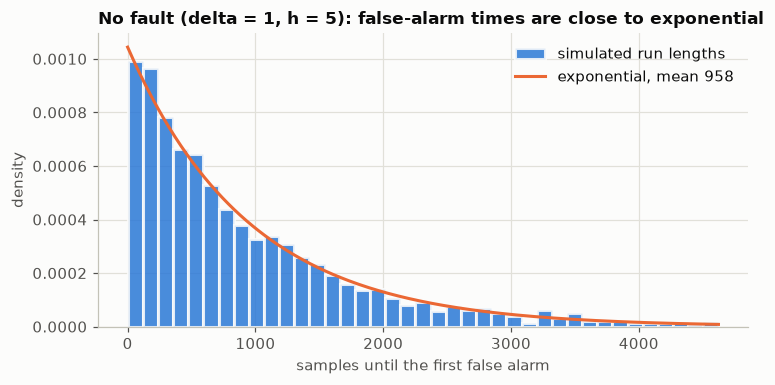

In [8]:
d, j = 1.0, list(H).index(5)
rl = run_lengths[d][:, j]
arl = rl.mean()
print(f"delta={d}, h=5: mean run length {arl:.0f}, sd {rl.std(ddof=1):.0f}, sd/mean {rl.std(ddof=1) / arl:.2f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(0, np.quantile(rl, 0.99), 40)
ax.hist(rl, bins=bins, density=True, color=BLUE, alpha=0.85, edgecolor=SURFACE, linewidth=2,
        label="simulated run lengths")
t = np.linspace(0, bins[-1], 300)
ax.plot(t, np.exp(-t / arl) / arl, color=ORANGE, label=f"exponential, mean {arl:.0f}")
ax.set_xlabel("samples until the first false alarm")
ax.set_ylabel("density")
ax.set_title("No fault (delta = 1, h = 5): false-alarm times are close to exponential")
ax.legend()
fig.tight_layout()
save_fig(fig, "fig2_run_length_hist")
plt.show()

The run length to false alarm is close to exponential (memoryless), with standard deviation ≈ mean. So false alarms arrive roughly like a Poisson process with rate 1/ARL, and "false-alarm rate ≈ 1/ARL" is a fair one-number summary. It also means a single run tells you very little: ARL estimates need many runs.

## 6. Theory vs simulation

Delay against log(ARL), one panel per fault size. Each dot is one threshold $h$ (2 to 8, left to right); its 95% confidence interval is drawn but smaller than the dot. The lines are the two theory predictions.

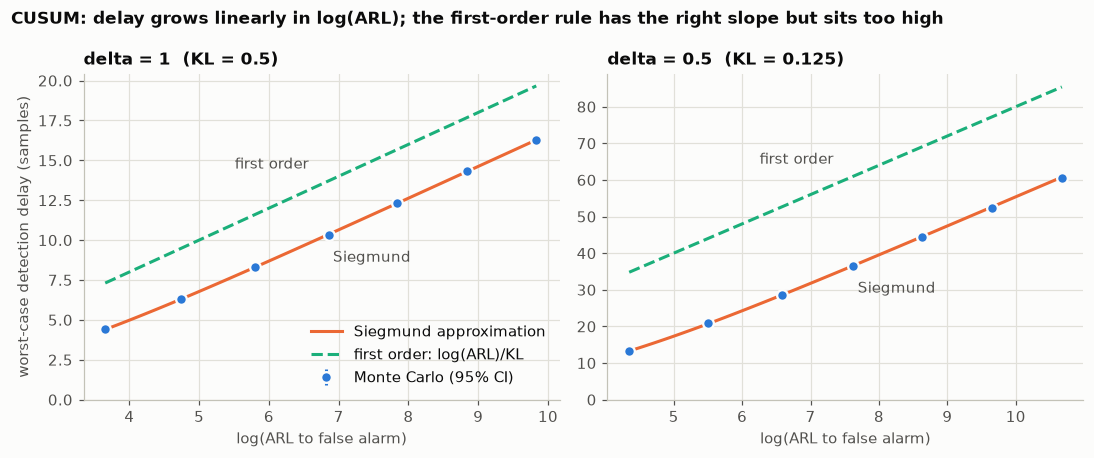

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
hh = np.linspace(H.min(), H.max(), 100)
for ax, d in zip(axes, DELTAS):
    m = mc[mc.delta == d]
    KLd = d**2 / 2
    ax.plot(np.log(siegmund_run_length(hh, d, 0.0)), siegmund_run_length(hh, d, d),
            color=ORANGE, label="Siegmund approximation")
    la = np.linspace(np.log(m.arl_mc.min()), np.log(m.arl_mc.max()), 2)
    ax.plot(la, la / KLd, color=AQUA, ls="--", label="first order: log(ARL)/KL")
    ax.errorbar(np.log(m.arl_mc), m.delay_mc, yerr=m.delay_ci, fmt="o", color=BLUE,
                mec=SURFACE, mew=1.5, capsize=0, label="Monte Carlo (95% CI)", zorder=3)
    ax.set_title(f"delta = {d:g}  (KL = {KLd:g})")
    ax.set_xlabel("log(ARL to false alarm)")
    ax.set_ylim(bottom=0)
    # direct labels at mid-range: first order above its line, Siegmund below its curve
    xm = la.mean()
    ax.annotate("first order", (xm, xm / KLd), xytext=(-8, 8), textcoords="offset points",
                color=INK2, ha="right", va="bottom")
    xs, ys = np.log(siegmund_run_length(hh, d, 0.0)), siegmund_run_length(hh, d, d)
    ax.annotate("Siegmund", (xm, np.interp(xm, xs, ys)), xytext=(8, -8), textcoords="offset points",
                color=INK2, ha="left", va="top")
axes[0].set_ylabel("worst-case detection delay (samples)")
axes[0].legend(loc="lower right")
fig.suptitle("CUSUM: delay grows linearly in log(ARL); the first-order rule has the right slope but sits too high",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig3_delay_vs_log_arl")
plt.show()

In [10]:
cmp = mc.assign(
    arl_err_pct=100 * (mc.arl_siegmund / mc.arl_mc - 1),
    delay_err_pct=100 * (mc.delay_siegmund / mc.delay_mc - 1),
    first_order_over_mc=mc.delay_first_order / mc.delay_mc,
)[["delta", "h", "arl_mc", "arl_siegmund", "arl_err_pct", "delay_mc", "delay_siegmund", "delay_err_pct",
   "delay_first_order", "first_order_over_mc"]]
cmp.round(2)

,delta,h,arl_mc,arl_siegmund,arl_err_pct,delay_mc,delay_siegmund,delay_err_pct,delay_first_order,first_order_over_mc
0,1.0,2,38.66,39.09,1.13,4.42,4.42,-0.16,7.31,1.65
1,1.0,3,114.53,118.58,3.54,6.34,6.36,0.40,9.48,1.50
2,1.0,4,330.35,338.09,2.34,8.29,8.34,0.68,11.60,1.40
3,1.0,5,958.20,938.22,-2.09,10.31,10.34,0.24,13.73,1.33
4,1.0,6,2525.80,2572.98,1.87,12.32,12.33,0.12,15.67,1.27
5,1.0,7,6918.90,7020.15,1.46,14.33,14.33,0.03,17.68,1.23
6,1.0,8,18617.30,19112.23,2.66,16.27,16.33,0.41,19.66,1.21
7,0.5,2,77.43,77.23,-0.26,13.19,13.27,0.59,34.80,2.64
8,0.5,3,246.35,251.19,1.97,20.82,20.89,0.34,44.05,2.12
9,0.5,4,723.32,737.80,2.00,28.68,28.75,0.21,52.67,1.84


**Where the gap comes from.** For large $h$, Siegmund's formula simplifies to $\log \text{ARL} \approx h + 1.166\delta - \log \text{KL}$ and $\text{KL}\cdot\text{delay} \approx h + 1.166\delta - 1$. Subtracting the two gives a constant offset:

$$\log \text{ARL} - \text{KL}\cdot\text{delay} \;\approx\; 1 - \log \text{KL}
\qquad\Longleftrightarrow\qquad
\text{delay} \approx \frac{\log(\text{KL}\cdot\text{ARL}) - 1}{\text{KL}}.$$

The first-order rule drops this offset. Check it on the simulated numbers:

In [11]:
offset = np.log(mc.arl_mc) - mc.KL * mc.delay_mc
for d in DELTAS:
    sel = mc.delta == d
    print(f"delta={d}: simulated offset at h=2..8: {np.round(offset[sel].values, 2)}  "
          f"->  large-h theory 1 - log KL = {1 - np.log(d**2 / 2):.2f}")

delta=1.0: simulated offset at h=2..8: [1.44 1.57 1.66 1.71 1.67 1.68 1.7 ]  ->  large-h theory 1 - log KL = 1.69
delta=0.5: simulated offset at h=2..8: [2.7  2.9  3.   3.04 3.07 3.11 3.11]  ->  large-h theory 1 - log KL = 3.08


**What the simulation shows**

- **Siegmund's approximation matches the Monte Carlo** at every threshold and both fault sizes: ARL within 3.6% (inside the ±4.5% Monte Carlo interval) and delay within 0.7%. The formula quoted from memory is now checked, for iid Gaussian data.
- **The first-order rule log(ARL)/KL overestimates the delay at every threshold here:** by 21–65% for δ = 1 and by 41–164% for δ = 0.5. The error shrinks only slowly as the ARL grows.
- **The gap is a constant offset of about 1 − log KL** (1.69 for δ = 1, 3.08 for δ = 0.5); the simulated offsets approach these values as h grows (1.70 and 3.11 at h = 8). Small faults, with small KL, have the largest offset.

**What this means for the project**

- Rank detectors by **simulated** delay at the **same simulated ARL**, not by the formula.
- A KL ratio, like the coupled-detector gain table in `docs/project_reference.md`, predicts the ratio of *slopes*. At a practical ARL (10² to 10⁴) the offset term depends on KL, and plugging numbers into the formula above suggests the realised speed-up will be *smaller* than the KL ratio (for the ρ = 0.9 single-slice fault at ARL 1000, the formula gives about 4× instead of 5.3×). Task 3 measures this by Monte Carlo.

## 7. What breaks it: correlated noise

Same CUSUM, same threshold ($\delta = 1$, $h = 4$), but now the noise has memory: AR(1), $e_n = \phi\, e_{n-1} + \sqrt{1-\phi^2}\, z_n$. Each sample on its own is still $\mathcal N(0,1)$; only the correlation between neighbours changes. Queue latencies behave like this, because Lindley's recursion acts like a (nonlinear) low-pass filter.

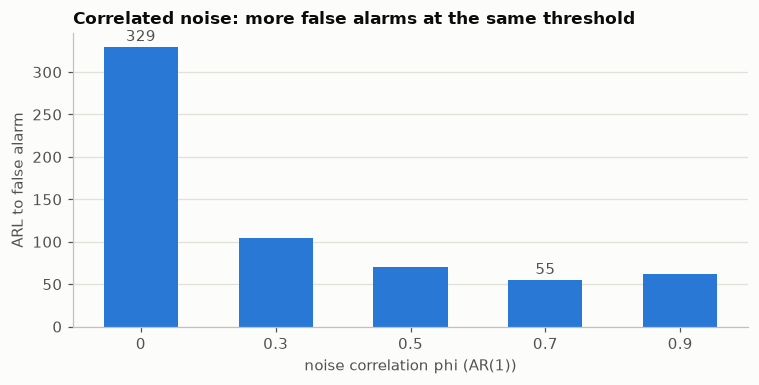

,phi,arl_mc,arl_ci,p_alarm_within_10,dc_psd
0,0.0,329.37,14.17,0.01,1.00
1,0.3,104.58,4.42,0.08,1.86
2,0.5,70.13,2.86,0.10,3.00
3,0.7,54.80,2.27,0.14,5.67
4,0.9,61.49,2.79,0.17,19.00


In [12]:
PHIS = [0.0, 0.3, 0.5, 0.7, 0.9]
ar = []
for i, phi in enumerate(PHIS):
    T = cusum_alarm_times(1.0, [4.0], R_ARL, rng_for(30 + i), phi=phi)[:, 0]
    arl, ci = mean_ci(T)
    ar.append(dict(phi=phi, arl_mc=arl, arl_ci=ci, p_alarm_within_10=np.mean(T <= 10),
                   dc_psd=(1 + phi) / (1 - phi)))
ar = pd.DataFrame(ar)
ar.to_csv(OUT / "ar1_arl.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar([f"{p:g}" for p in ar.phi], ar.arl_mc, width=0.55, color=BLUE)
ax.grid(axis="x", visible=False)
for k in [0, PHIS.index(0.7)]:
    ax.annotate(f"{ar.arl_mc[k]:.0f}", (k, ar.arl_mc[k]), xytext=(0, 4), textcoords="offset points",
                ha="center", color=INK2)
ax.set_xlabel("noise correlation phi (AR(1))")
ax.set_ylabel("ARL to false alarm")
ax.set_title("Correlated noise: more false alarms at the same threshold")
fig.tight_layout()
save_fig(fig, "fig4_ar1_arl")
plt.show()
ar.round(2)

**What happened.** At the same threshold, the ARL falls from about 330 (white noise) to about 105 at $\phi = 0.3$ and 55 at $\phi = 0.7$: 3× and 6× more false alarms, although every sample still has variance 1.

**Why.** CUSUM is a running sum, i.e. a low-pass filter, so it mainly responds to the noise power at low frequencies, not to the variance. For unit-variance AR(1) noise the power spectral density at DC is $(1+\phi)/(1-\phi)$ (column `dc_psd`): about 5.7 at $\phi = 0.7$, versus 1 for white noise. A slow noise wander looks like a small mean shift, and CUSUM accumulates it.

**Why the ARL rises again at φ = 0.9.** That low-frequency argument assumes the noise forgets faster than CUSUM accumulates. At $\phi = 0.9$ the noise is so slow that a run starting in a low stretch can wait a long time before the noise wanders above the reference level $\delta/2$, which pulls the *mean* run length back up. Early false alarms still keep getting more likely (column `p_alarm_within_10`). The ARL alone hides this, which is one more reason to look at the whole run-length distribution, not only its mean.

**Lesson for the project:** the false-alarm rate depends on the noise's memory, not just its variance, so the iid formulas cannot set thresholds on raw latencies. Whiten first (feed CUSUM the residuals of an AR/Kalman model of normal behaviour), and set thresholds by simulation on fault-free data.

## 8. When the change happens later

The evaluation plan uses **conditional delay**: the fault starts at a fixed time $\nu$ (here 200), and we average $T - \nu$ over the runs that did *not* raise a false alarm before $\nu$. Compare it with the worst case from section 5 ($\nu = 0$).

In [13]:
d, h, nu_late = 1.0, 6.0, 200
T = cusum_alarm_times(d, [h], R_DELAY, rng_for(40), shift=d, change_time=nu_late)[:, 0]
ok = T > nu_late
cadd, cadd_ci = mean_ci(T[ok] - nu_late)
worst = mc[(mc.delta == d) & (mc.h == h)].iloc[0]
print(f"delta={d}, h={h:g}")
print(f"  runs with a false alarm before n={nu_late}: {100 * (~ok).mean():.1f}%  (dropped)")
print(f"  conditional delay, change at n={nu_late}: {cadd:.2f} +/- {cadd_ci:.2f}")
print(f"  worst-case delay, change at n=0:        {worst.delay_mc:.2f} +/- {worst.delay_ci:.2f}")

delta=1.0, h=6
  runs with a false alarm before n=200: 7.6%  (dropped)
  conditional delay, change at n=200: 11.71 +/- 0.18
  worst-case delay, change at n=0:        12.32 +/- 0.17


The conditional delay (about 11.7 samples) is shorter than the worst case (about 12.3). At $n = 200$ the statistic is often somewhere above 0 (it is a reflected random walk), so it starts closer to $h$. Both numbers are legitimate; a results table must say which one it reports. Our evaluation uses conditional delay at a fixed $\nu$, and reports the fraction of runs dropped for early false alarms.

In [14]:
# Export tables and key numbers for report/main.tex (figures were exported as they were drawn)
tab = pd.DataFrame({
    r"$\delta$": mc.delta.map("{:g}".format),
    r"$h$": mc.h.astype(str),
    "ARL (MC)": [f"{a:,.0f} $\\pm$ {c:,.0f}" for a, c in zip(mc.arl_mc, mc.arl_ci)],
    "ARL (Siegmund)": mc.arl_siegmund.map("{:,.0f}".format),
    "delay (MC)": [f"{a:.2f} $\\pm$ {c:.2f}" for a, c in zip(mc.delay_mc, mc.delay_ci)],
    "delay (Siegmund)": mc.delay_siegmund.map("{:.2f}".format),
    "delay (first order)": mc.delay_first_order.map("{:.2f}".format),
})
save_tex_table(tab, "theory_vs_mc", "rrrrrrr")

tab = pd.DataFrame({
    r"$\phi$": ar.phi.map("{:g}".format),
    "ARL (MC)": [f"{a:.0f} $\\pm$ {c:.0f}" for a, c in zip(ar.arl_mc, ar.arl_ci)],
    r"$P(T \le 10)$": ar.p_alarm_within_10.map("{:.2f}".format),
    r"$(1+\phi)/(1-\phi)$": ar.dc_psd.map("{:.2f}".format),
})
save_tex_table(tab, "ar1", "rrrr")

fo = cmp.first_order_over_mc
off = np.log(mc.arl_mc) - mc.KL * mc.delay_mc
pct = lambda x: f"{100 * x:.0f}"
save_tex_numbers({
    "CusumSiegArlMaxErr": f"{cmp.arl_err_pct.abs().max():.1f}",
    "CusumSiegDelayMaxErr": f"{cmp.delay_err_pct.abs().max():.1f}",
    "CusumFOOneLo": pct(fo[cmp.delta == 1.0].min() - 1), "CusumFOOneHi": pct(fo[cmp.delta == 1.0].max() - 1),
    "CusumFOHalfLo": pct(fo[cmp.delta == 0.5].min() - 1), "CusumFOHalfHi": pct(fo[cmp.delta == 0.5].max() - 1),
    "CusumOffsetOne": f"{off[(mc.delta == 1.0) & (mc.h == 8)].iloc[0]:.2f}",
    "CusumOffsetHalf": f"{off[(mc.delta == 0.5) & (mc.h == 8)].iloc[0]:.2f}",
    "CusumOffsetOneTheory": f"{1 - np.log(0.5):.2f}", "CusumOffsetHalfTheory": f"{1 - np.log(0.125):.2f}",
    "ArOneIid": f"{ar.arl_mc[0]:.0f}", "ArOnePointThree": f"{ar.arl_mc[1]:.0f}",
    "ArOnePointSeven": f"{ar.arl_mc[3]:.0f}",
    "CaddLate": f"{cadd:.1f}", "CaddWorst": f"{worst.delay_mc:.1f}", "CaddDropped": f"{100 * (~ok).mean():.1f}",
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("01_*")))

exported: ['01_ar1.tex', '01_numbers.tex', '01_theory_vs_mc.tex']


## 9. Summary

- **KL = δ²/2 is the evidence per sample.** CUSUM adds it up with resets at 0, which is Lindley's queue recursion.
- **On iid Gaussian data, Siegmund's approximation matches the simulation** within Monte Carlo error. The first-order rule log(ARL)/KL has the right shape but overestimates delay by 20–160% at practical ARLs, worst for small faults. The missing piece is an offset of about 1 − log KL.
- **False-alarm times are close to exponential**, so false-alarm rate ≈ 1/ARL, and estimating ARL needs many runs.
- **Correlated noise breaks the iid calibration:** at the same threshold the ARL drops from about 330 to about 55 at φ = 0.7. Whiten first, and set thresholds by simulation.
- **Conditional delay** (fault at n = 200) is a little shorter than the worst case (11.7 vs 12.3 samples at h = 6). Always state which one you report.

### Try it yourself
1. **Mis-tuned detector.** Keep the CUSUM tuned for $\delta = 1$, but make the true shift 0.5 (then 2). Predict first: how much slower or faster than a CUSUM tuned to the true shift? Then simulate with `cusum_alarm_times(1.0, H, ..., shift=0.5)`. This is why the project needs GLR-CUSUM or a bank of CUSUMs.
2. **Noise with σ = 2.** What is the KL now? Change `llr` accordingly and check that the delay scales as you predict.
3. **Whitening.** For AR(1) noise with $\phi = 0.7$, feed CUSUM $u_n = (x_n - \phi x_{n-1})/\sqrt{1-\phi^2}$. Check that the ARL returns to the iid value. What happens to the size of the shift after whitening, and so to the delay?
4. **Shiryaev–Roberts.** Replace the CUSUM update with $R_n = (1 + R_{n-1})\,e^{\ell(x_n)}$, $R_0 = 0$, alarm when $R_n \ge A$. Compare its delay-vs-log(ARL) curve with CUSUM's.